# Academic Research Trends

**Topic:** Academic Research Trends: University Characteristics and Research Output in Germany

**Sources:** [Wikipedia universities](https://en.wikipedia.org/wiki/List_of_universities_in_Germany) and [OpenAlex API](https://api.openalex.org)

**Research questions**
1. Which matched German universities have the highest number of publications?
2. Is university size associated with the number of publications?
3. How did publication counts change from 2020 to 2025 for the matched universities?


## 1. Imported libraries

In [1]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import re

pd.set_option("display.max_columns", None)

## 2. Scraped university data from Wikipedia

Source:  
https://en.wikipedia.org/wiki/List_of_universities_in_Germany

In [2]:
wiki_url = "https://en.wikipedia.org/wiki/List_of_universities_in_Germany"

headers = {
    "User-Agent": "Mozilla/5.0 AcademicResearchTrendsStudentProject/1.0"
}

response = requests.get(wiki_url, headers=headers, timeout=30)
response.raise_for_status()

soup = BeautifulSoup(response.text, "html.parser")

tables = soup.find_all("table", class_="wikitable")
print("Number of wikitable tables found:", len(tables))

Number of wikitable tables found: 1


In [3]:

table = tables[0]

rows = []

for tr in table.find_all("tr")[1:]:
    cells = tr.find_all(["td", "th"])
    values = [cell.get_text(" ", strip=True) for cell in cells]


    if len(values) >= 6:
        rows.append({
            "university": values[0],
            "city": values[1],
            "type": values[3],
            "founded_year": values[4],
            "students": values[5]
        })

wiki_df = pd.DataFrame(rows)

print("Rows collected:", len(wiki_df))
wiki_df.head()

Rows collected: 124


,university,city,type,founded_year,students
0,RWTH Aachen University,Aachen,public,1870,"47,000"
1,Augsburg University,Augsburg,public,1970,"20,000"
2,University of Bamberg,Bamberg,public,1972,"12,000"
3,University of Bayreuth,Bayreuth,public,1975,"13,000"
4,Bard College Berlin,Berlin,private,1999,400


## 3. Cleaned data from Wikipedia

- extracted a four-digit founding year
- converted student counts to numbers
- removed duplicates

In [4]:
wiki_df["founded_year"] = (
    wiki_df["founded_year"]
    .str.extract(r"(\d{4})", expand=False)
)

wiki_df["founded_year"] = pd.to_numeric(
    wiki_df["founded_year"],
    errors="coerce"
)


wiki_df["students"] = (
    wiki_df["students"]
    .str.replace(",", "", regex=False)
    .str.extract(r"(\d+)", expand=False)
)

wiki_df["students"] = pd.to_numeric(
    wiki_df["students"],
    errors="coerce"
)


wiki_df = wiki_df.drop_duplicates(subset="university").reset_index(drop=True)

print(wiki_df.shape)
wiki_df.head()

(124, 5)


,university,city,type,founded_year,students
0,RWTH Aachen University,Aachen,public,1870,47000
1,Augsburg University,Augsburg,public,1970,20000
2,University of Bamberg,Bamberg,public,1972,12000
3,University of Bayreuth,Bayreuth,public,1975,13000
4,Bard College Berlin,Berlin,private,1999,400


In [5]:

print("Missing values:")
display(wiki_df.isna().sum())

print("\nData types:")
display(wiki_df.dtypes)

Missing values:


,0
university,0
city,0
type,0
founded_year,0
students,0



Data types:


,0
university,object
city,object
type,object
founded_year,int64
students,int64


## 4. Selected universities for the project

Used up to 40 universities with available student counts.

In [6]:
selected_df = (
    wiki_df
    .dropna(subset=["students"])
    .sort_values("students", ascending=False)
    .head(40)
    .reset_index(drop=True)
)

print("Universities selected:", len(selected_df))
selected_df[["university", "city", "founded_year", "students"]].head(40)

Universities selected: 40


,university,city,founded_year,students
0,University of Hagen,Hagen,1974,72000
1,LMU Munich,Munich,1472,53000
2,TU Munich,Munich,1868,52000
3,RWTH Aachen University,Aachen,1870,47000
4,Goethe University Frankfurt,Frankfurt (Main),1914,46000
5,University of Cologne,Cologne,1388,43500
6,University of Münster,Münster,1780,43000
7,Ruhr University Bochum,Bochum,1962,43000
8,University of Duisburg-Essen,"Duisburg , Essen",2003,42000
9,University of Hamburg,Hamburg,1919,42000


## 5. Collect OpenAlex data

Wikipedia university names are the starting point. Keep a university only when its name matches an OpenAlex main or alternative name after simple text normalization.

In [8]:
API_KEY = ""  # I gained my API Key, but removed it before sharing to Teams and Github

OPENALEX_INSTITUTIONS = "https://api.openalex.org/institutions"
OPENALEX_WORKS = "https://api.openalex.org/works"

if not API_KEY:
    raise ValueError("Paste your API key into API_KEY")

def get_data(url, params):
    for attempt in range(5):
        response = requests.get(url, params=params, timeout=30)
        if response.status_code == 429:
            wait = int(response.headers.get("Retry-After", 2 ** (attempt + 1)))
            time.sleep(min(wait, 60))
            continue
        response.raise_for_status()
        time.sleep(0.4)
        return response.json()
    raise RuntimeError("OpenAlex API limit. Check key.")

In [9]:
# Ignore capitalization, punctuation and repeated spaces in name comparisons
def clean_name(name):
    name = str(name).casefold()
    name = re.sub(r"[^\w\s]", " ", name)
    return " ".join(name.split())


In [10]:
research_rows = []

for university in selected_df["university"]:
    params = {
        "api_key": API_KEY,
        "search": university,
        "filter": "country_code:DE,type:education",
        "per_page": 25
    }
    data = get_data(OPENALEX_INSTITUTIONS, params)

    match = None
    wikipedia_name = clean_name(university)

    for candidate in data["results"]:
        names = [candidate["display_name"]]
        names += candidate.get("display_name_alternatives") or []
        names += candidate.get("display_name_acronyms") or []

        for name in names:
            if clean_name(name) == wikipedia_name:
                match = candidate
                break
        if match is not None:
            break

    if match is not None:
        research_rows.append({
            "university": university,
            "openalex_name": match["display_name"],
            "openalex_id": match["id"].split("/")[-1]
        })

openalex_df = pd.DataFrame(
    research_rows,
    columns=["university", "openalex_name", "openalex_id"]
)

print("Selected on Wikipedia:", len(selected_df))
print("Accepted name matches:", len(openalex_df))
print("Not matched:", len(selected_df) - len(openalex_df))
display(openalex_df)


Selected on Wikipedia: 40
Accepted name matches: 33
Not matched: 7


,university,openalex_name,openalex_id
0,University of Hagen,FernUniversität in Hagen,I120691247
1,LMU Munich,Ludwig-Maximilians-Universität München,I8204097
2,RWTH Aachen University,RWTH Aachen University,I887968799
3,Goethe University Frankfurt,Goethe University Frankfurt,I114090438
4,University of Cologne,University of Cologne,I180923762
5,University of Münster,University of Münster,I22465464
6,Ruhr University Bochum,Ruhr University Bochum,I904495901
7,University of Duisburg-Essen,University of Duisburg-Essen,I62318514
8,University of Hamburg,Universität Hamburg,I159176309
9,University of Bonn,University of Bonn,I135140700


In [11]:
# Universities excluded because no name match was found
unmatched_df = selected_df[~selected_df["university"].isin(openalex_df["university"])]
display(unmatched_df[["university", "city"]])


,university,city
2,TU Munich,Munich
10,University of Erlangen-Nürnberg,"Erlangen , Nuremberg"
14,Herinrich Heine University Düsseldorf,Düsseldorf
18,University of Mainz,Mainz
35,Marburg University,Marburg
37,Augsburg University,Augsburg
38,University of Paderborn,Paderborn


In [12]:
# Accepted Wikipedia  OpenAlex name pairs
display(openalex_df[["university", "openalex_name", "openalex_id"]])


,university,openalex_name,openalex_id
0,University of Hagen,FernUniversität in Hagen,I120691247
1,LMU Munich,Ludwig-Maximilians-Universität München,I8204097
2,RWTH Aachen University,RWTH Aachen University,I887968799
3,Goethe University Frankfurt,Goethe University Frankfurt,I114090438
4,University of Cologne,University of Cologne,I180923762
5,University of Münster,University of Münster,I22465464
6,Ruhr University Bochum,Ruhr University Bochum,I904495901
7,University of Duisburg-Essen,University of Duisburg-Essen,I62318514
8,University of Hamburg,Universität Hamburg,I159176309
9,University of Bonn,University of Bonn,I135140700


## 6. Collect publication counts

Counted publications through the OpenAlex Works API for accepted institutions only.

In [13]:
publication_counts = []

for openalex_id in openalex_df["openalex_id"]:
    params = {
        "api_key": API_KEY,
        "filter": "institutions.id:" + openalex_id,
        "per_page": 1
    }
    data = get_data(OPENALEX_WORKS, params)
    publication_counts.append(data["meta"]["count"])

openalex_df["works_count"] = publication_counts
openalex_df.head()

,university,openalex_name,openalex_id,works_count
0,University of Hagen,FernUniversität in Hagen,I120691247,12505
1,LMU Munich,Ludwig-Maximilians-Universität München,I8204097,304515
2,RWTH Aachen University,RWTH Aachen University,I887968799,194151
3,Goethe University Frankfurt,Goethe University Frankfurt,I114090438,153456
4,University of Cologne,University of Cologne,I180923762,135443


## 7. Merge Wikipedia and OpenAlex datasets

Use an inner join: unmatched universities are excluded from all further analysis.

In [14]:
merged_df = selected_df.merge(openalex_df, on="university", how="inner")
print("Universities in analysis:", len(merged_df))
display(merged_df.head())

Universities in analysis: 33


,university,city,type,founded_year,students,openalex_name,openalex_id,works_count
0,University of Hagen,Hagen,public,1974,72000,FernUniversität in Hagen,I120691247,12505
1,LMU Munich,Munich,public,1472,53000,Ludwig-Maximilians-Universität München,I8204097,304515
2,RWTH Aachen University,Aachen,public,1870,47000,RWTH Aachen University,I887968799,194151
3,Goethe University Frankfurt,Frankfurt (Main),public,1914,46000,Goethe University Frankfurt,I114090438,153456
4,University of Cologne,Cologne,public,1388,43500,University of Cologne,I180923762,135443


In [15]:
# Final missing-value check
merged_df.isna().sum()

,0
university,0
city,0
type,0
founded_year,0
students,0
openalex_name,0
openalex_id,0
works_count,0


## 8. Descriptive statistics

In [16]:
merged_df[["students", "founded_year", "works_count"]].describe().round(2)

,students,founded_year,works_count
count,33.0,33.00,33.00
mean,33000.0,1782.70,120219.61
std,11314.4,210.94,60923.87
min,20000.0,1386.00,12505.00
25%,25000.0,1665.00,74772.00
50%,30000.0,1831.00,125871.00
75%,42000.0,1962.00,153456.00
max,72000.0,2009.00,304515.00


## 9. Universities by number of publications

In [17]:
top_10 = merged_df.sort_values("works_count", ascending=False).head(10)
display(top_10[["university", "works_count"]])

,university,works_count
1,LMU Munich,304515
16,University of Heidelberg,238924
2,RWTH Aachen University,194151
9,University of Bonn,180952
19,University of Tübingen,169096
18,University of Göttingen,168627
26,University of Freiburg,165008
27,Karlsruhe Institute of Technology,158527
3,Goethe University Frankfurt,153456
5,University of Münster,142161


## Visualization 1 : Top universities by research output

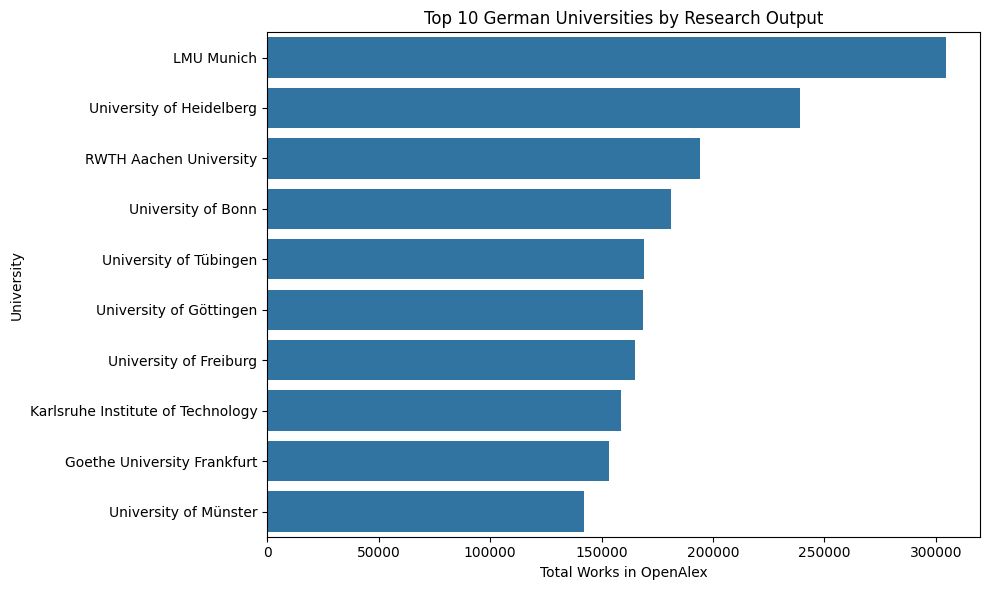

In [18]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_10,
    x="works_count",
    y="university"
)

plt.title("Top 10 German Universities by Research Output")
plt.xlabel("Total Works in OpenAlex")
plt.ylabel("University")
plt.tight_layout()
plt.show()

## 10. Correlation analysis

Compare student population (Wikipedia) and total publication counts (OpenAlex).

In [19]:
correlation_columns = ["students", "works_count"]
correlations = merged_df[correlation_columns].corr()
correlations.round(2)

,students,works_count
students,1.00,0.23
works_count,0.23,1.00


## Visualization 2 : Correlation heatmap

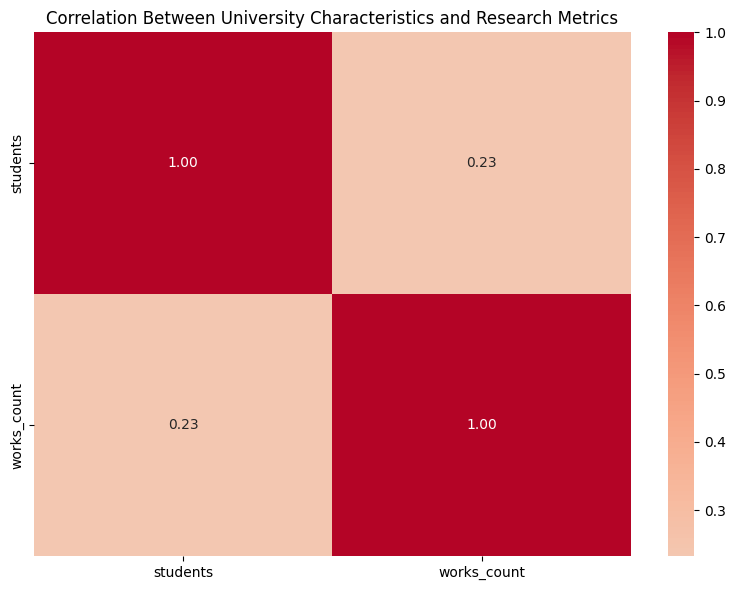

In [20]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlations,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Between University Characteristics and Research Metrics")
plt.tight_layout()
plt.show()

## Visualization 3 : University size vs research output

This plot directly combines:
- `students` from Wikipedia
- `works_count` from OpenAlex

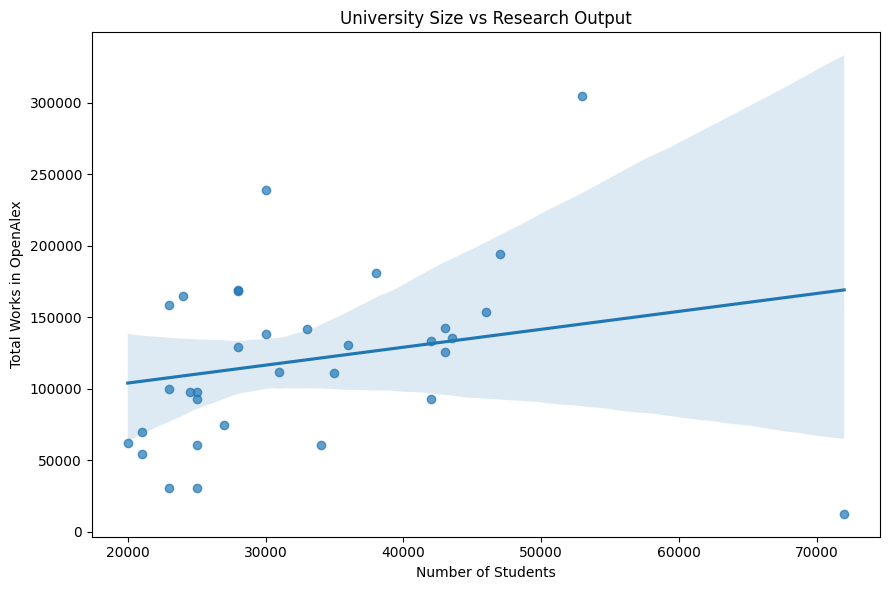

Correlation: 0.233


In [21]:
plot_df = merged_df.dropna(subset=["students", "works_count"])

plt.figure(figsize=(9, 6))

sns.regplot(
    data=plot_df,
    x="students",
    y="works_count",
    scatter_kws={"alpha": 0.7}
)

plt.title("University Size vs Research Output")
plt.xlabel("Number of Students")
plt.ylabel("Total Works in OpenAlex")
plt.tight_layout()
plt.show()

size_output_corr = plot_df["students"].corr(plot_df["works_count"])
print("Correlation:", round(size_output_corr, 3))

## 11. Publication trends from 2020 to 2025

Count publications per year for the accepted university matches.

In [22]:
trend_rows = []

for _, row in openalex_df.iterrows():
    params = {
        "api_key": API_KEY,
        "filter": "institutions.id:" + row["openalex_id"] + ",publication_year:2020-2025",
        "group_by": "publication_year"
    }
    data = get_data(OPENALEX_WORKS, params)

    for result in data.get("group_by", []):
        year = int(result["key"])
        if 2020 <= year <= 2025:
            trend_rows.append({
                "university": row["university"],
                "year": year,
                "publications": result["count"]
            })

trends_df = pd.DataFrame(trend_rows, columns=["university", "year", "publications"])
trends_df.head()


,university,year,publications
0,University of Hagen,2025,786
1,University of Hagen,2022,631
2,University of Hagen,2024,606
3,University of Hagen,2023,592
4,University of Hagen,2020,564


In [23]:
# Add years missing from the API result with zero publications
all_years = pd.MultiIndex.from_product(
    [openalex_df["university"], range(2020, 2026)],
    names=["university", "year"]
)
trends_df = trends_df.set_index(["university", "year"])
trends_df = trends_df.reindex(all_years, fill_value=0).reset_index()
print(trends_df.shape)
trends_df.head()


(198, 3)


,university,year,publications
0,University of Hagen,2020,564
1,University of Hagen,2021,510
2,University of Hagen,2022,631
3,University of Hagen,2023,592
4,University of Hagen,2024,606


## Visualization 4 : Publication trends for the top 5 matched universities

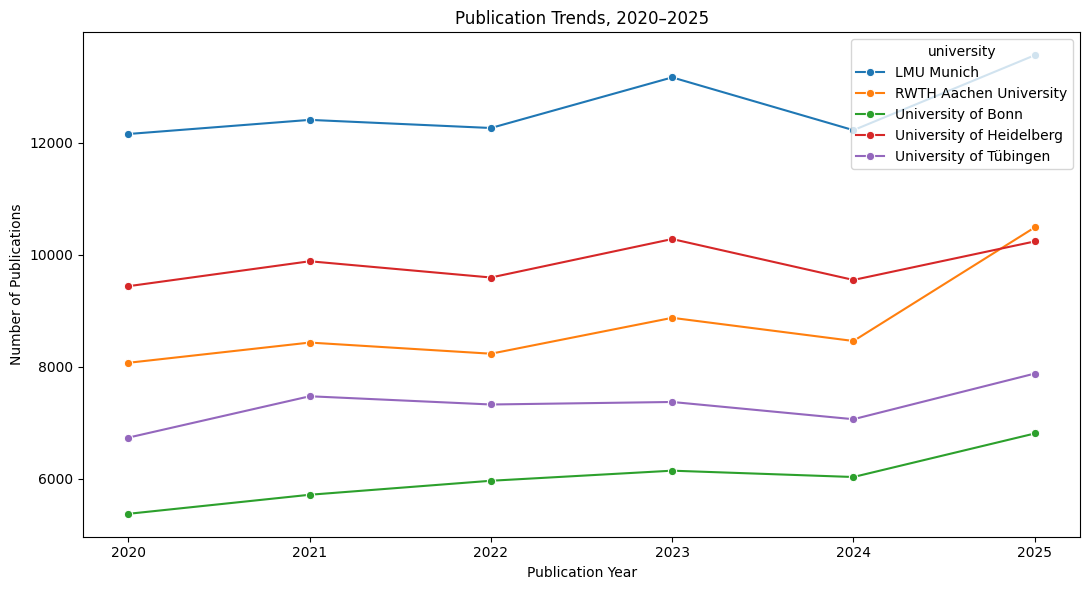

In [24]:
top_5_names = merged_df.nlargest(5, "works_count")["university"]
top_5_trends = trends_df[trends_df["university"].isin(top_5_names)]

plt.figure(figsize=(11, 6))
sns.lineplot(data=top_5_trends, x="year", y="publications", hue="university", marker="o")
plt.title("Publication Trends, 2020–2025")
plt.xlabel("Publication Year")
plt.ylabel("Number of Publications")
plt.xticks(range(2020, 2026))
plt.tight_layout()
plt.show()


## 12. Change in publication output

Compared publication counts in 2020 and 2025.

In [25]:
trend_change = trends_df.pivot(index="university", columns="year", values="publications")
trend_change["change_2020_2025"] = trend_change[2025] - trend_change[2020]
display(trend_change.sort_values("change_2020_2025", ascending=False).head(10))

year,2020,2021,2022,2023,2024,2025,change_2020_2025
university,,,,,,,
RWTH Aachen University,8068,8429,8230,8871,8457,10485,2417
University of Bonn,5371,5711,5961,6141,6028,6805,1434
LMU Munich,12154,12406,12261,13165,12222,13560,1406
Humboldt University of Berlin,6058,6759,6932,7128,6774,7283,1225
Karlsruhe Institute of Technology,6381,7470,6858,7361,7702,7591,1210
University of Tübingen,6732,7470,7323,7368,7060,7875,1143
TU Dresden,6863,7383,7398,7602,7566,7882,1019
University of Freiburg,5955,6445,6204,6468,6284,6957,1002
Kiel University,3434,3759,3554,3803,3734,4416,982


## 13. Save cleaned datasets

In [26]:
wiki_df.to_csv("wikipedia_universities_clean.csv", index=False)
openalex_df.to_csv("openalex_research_data.csv", index=False)
merged_df.to_csv("merged_university_research_data.csv", index=False)
trends_df.to_csv("publication_trends_2020_2025.csv", index=False)

print("CSV files saved.")
unmatched_df.to_csv("unmatched_wikipedia_universities.csv", index=False)


CSV files saved.
